# DeFi Exploit Trends 2016–2025: A Data-Driven Tour

**Author:** DefiAudit — DeFi security researcher & smart-contract auditor
**Dataset:** [DeFi & Smart Contract Security Dataset](https://www.kaggle.com/datasets/defiaudit/defi-smart-contract-security)

As a smart-contract auditor, I built this dataset to answer one question: *what actually breaks in DeFi, and what does it cost?*

This notebook walks through **70+ documented exploit incidents** (2016 → early 2025), the SWC vulnerability catalog, and the detection tooling landscape. Along the way we will answer:

1. How much value was lost per year, and is the trend accelerating?
2. Which attack categories dominate — and is reentrancy really 'solved'?
3. Which chains and protocol types get hit hardest?
4. How often is stolen value ever recovered?

> **TL;DR at the bottom** — but the charts tell the story better.


## 1 · Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import glob, os

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Robustly locate the dataset mount regardless of slug naming
csv_path = glob.glob('/kaggle/input/**/defi_exploits_2016_2025.csv', recursive=True)[0]
DATA = os.path.dirname(csv_path)
print('Dataset mounted at:', DATA)

df = pd.read_csv(f'{DATA}/defi_exploits_2016_2025.csv', parse_dates=['date'])
swc = pd.read_csv(f'{DATA}/smart_contract_vulnerability_patterns.csv')
tools = pd.read_csv(f'{DATA}/security_tooling_landscape.csv')

df['year'] = df['date'].dt.year
print('Incidents:', len(df), '| SWC patterns:', len(swc), '| Tools:', len(tools))
df.head(3)

Dataset mounted at: /kaggle/input/datasets/defiaudit/defi-smart-contract-security
Incidents: 71 | SWC patterns: 27 | Tools: 12


,date,protocol,org_type,defi_category,chain,primary_category,attack_vector,loss_usd_millions,recovered_usd_millions,resolution,notes,year
0,2016-06-17,The DAO,DeFi Protocol,VC Fund,Ethereum,Reentrancy,Unbounded external call before state update in...,60.0,0.0,Drained,3.6M ETH stolen; led to Ethereum hard fork and...,2016
1,2017-07-19,Parity Multisig (1st),Wallet,Wallet,Ethereum,Logic Error,Uninitialized wallet library contract could be...,31.8,0.0,Drained,"153,037 ETH stolen; initialized library became...",2017
2,2017-11-06,Parity Multisig (Freeze),Wallet,Wallet,Ethereum,Access Control,"User deleted shared library contract, freezing...",150.0,0.0,Frozen,"513,000+ ETH permanently frozen; still unspend...",2017


## 2 · The Big Picture

Total documented losses, average per incident, and the single largest event — the February 2025 Bybit/Safe{Wallet} infrastructure compromise ($1.46B) — which single-handedly distorts every average in this field.


In [2]:
total_loss = df['loss_usd_millions'].sum()
bybit = df.loc[df['loss_usd_millions'].idxmax()]
print(f"Total documented loss : ${total_loss/1000:.2f}B")
print(f"Largest single event  : {bybit['protocol']} ({bybit['date'].date()}) — ${bybit['loss_usd_millions']/1000:.2f}B")
print(f"Median incident       : ${df['loss_usd_millions'].median():.1f}M   (mean is misleading here)")
print(f"Fully returned share  : {(df['resolution']=='Fully Returned').mean()*100:.0f}% of incidents")

Total documented loss : $6.04B
Largest single event  : Bybit (Safe{Wallet}) (2025-02-21) — $1.46B
Median incident       : $20.0M   (mean is misleading here)
Fully returned share  : 4% of incidents


## 3 · Losses Over Time

Bars = number of incidents per year; line = total USD loss (log-friendly view). Note how **incident count** stays high while **loss size** spikes are driven by a handful of mega-events.


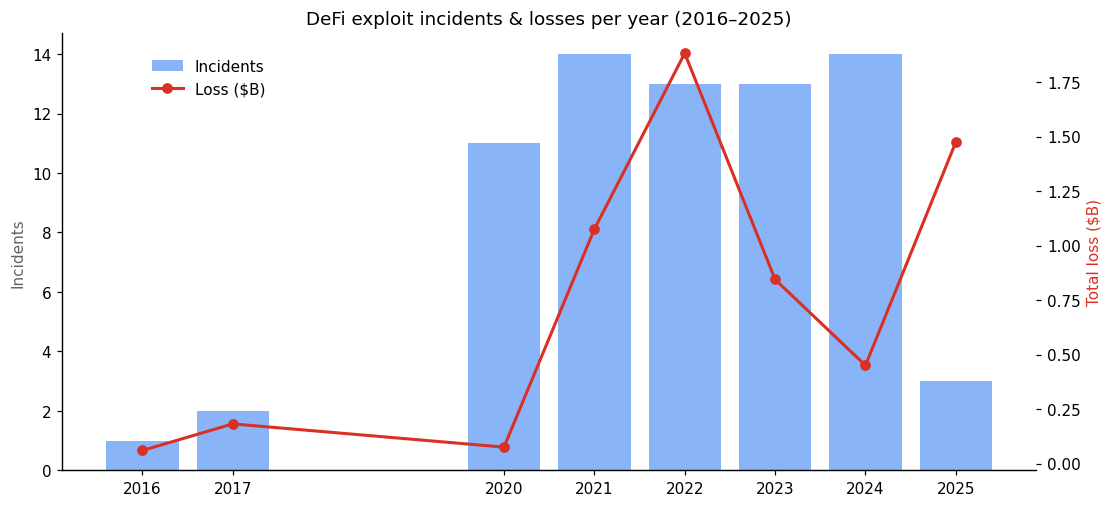

In [3]:
yearly = df.groupby('year').agg(incidents=('protocol','count'),
                               loss=('loss_usd_millions','sum'))

fig, ax1 = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax1.bar(yearly.index, yearly['incidents'], color='#8ab4f8', label='Incidents')
ax1.set_ylabel('Incidents', color='#5f6368')
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['loss']/1000, color='#d93025', marker='o', lw=2, label='Loss ($B)')
ax2.set_ylabel('Total loss ($B)', color='#d93025')
ax2.spines['top'].set_visible(False)
ax1.set_title('DeFi exploit incidents & losses per year (2016–2025)')
ax1.set_xticks(yearly.index)
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.92), frameon=False)
plt.show()

## 4 · The Hall of Shame

Top 15 most damaging incidents (log scale — even 'small' entries here are life-changing amounts).


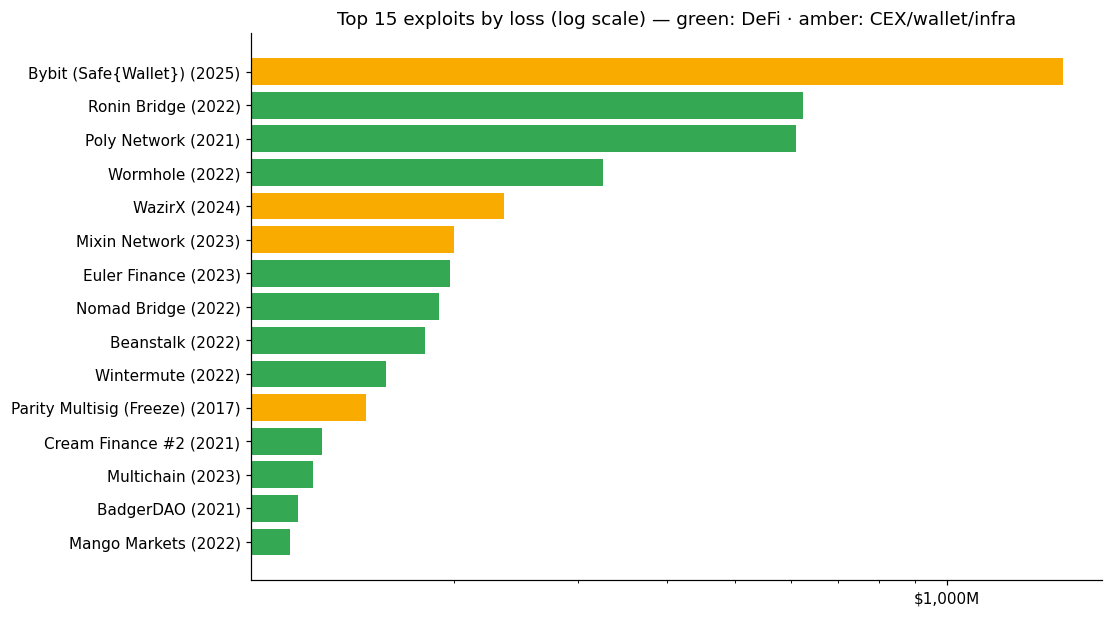

In [4]:
top15 = df.nlargest(15, 'loss_usd_millions').sort_values('loss_usd_millions')

fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
colors = np.where(top15['org_type'].isin(['CEX','Wallet','Infrastructure']), '#f9ab00', '#34a853')
ax.barh(top15['protocol'] + ' (' + top15['year'].astype(str) + ')',
        top15['loss_usd_millions'], color=colors)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'${v:,.0f}M'))
ax.set_title('Top 15 exploits by loss (log scale) — green: DeFi · amber: CEX/wallet/infra')
plt.show()

## 5 · Attack Categories: What Actually Breaks

Frequency vs impact. Reentrancy is the most *famous* class, but **key compromise** and **logic errors** dominate the money lost.


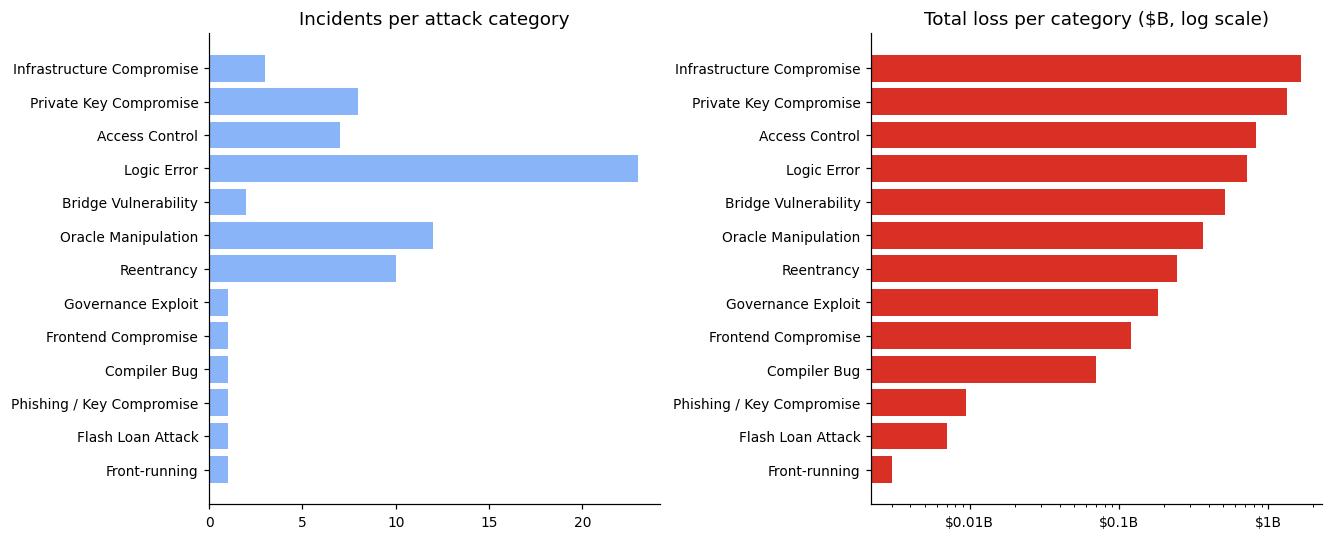

In [5]:
cats = df.groupby('primary_category').agg(incidents=('protocol','count'),
                                         loss=('loss_usd_millions','sum')).sort_values('loss')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].barh(cats.index, cats['incidents'], color='#8ab4f8')
axes[0].set_title('Incidents per attack category')
axes[1].barh(cats.index, cats['loss']/1000, color='#d93025')
axes[1].set_xscale('log')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v,_: f'${v:g}B'))
axes[1].set_title('Total loss per category ($B, log scale)')
for a in axes: a.tick_params(labelsize=9)
plt.show()

## 6 · Chains & Protocol Types

Ethereum still leads by count, but bridges and multi-chain infrastructure carry the single largest tail risks.


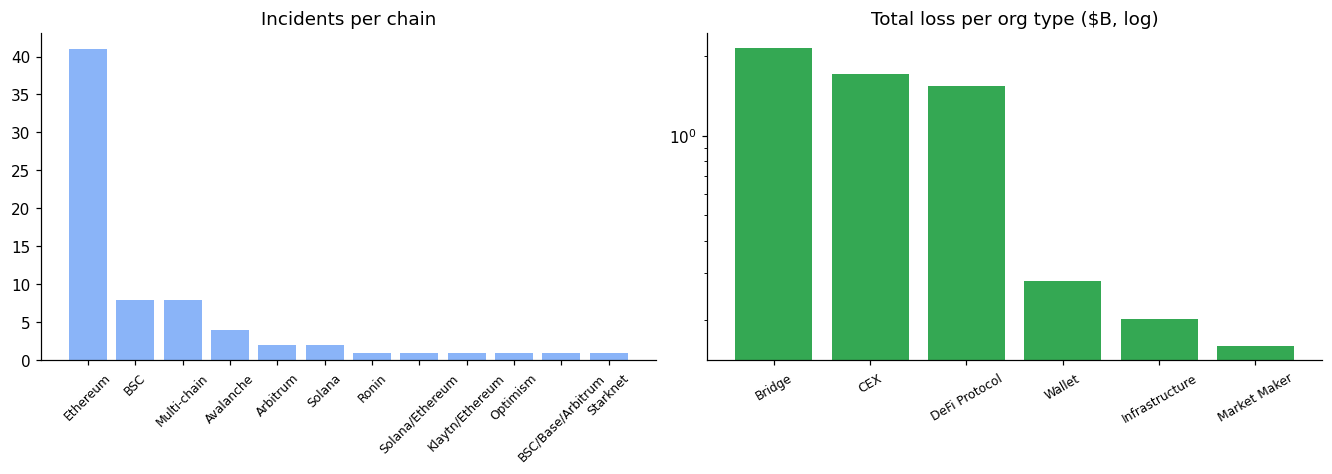

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
chain = df['chain'].value_counts()
axes[0].bar(chain.index, chain.values, color='#8ab4f8')
axes[0].set_title('Incidents per chain')
axes[0].tick_params(axis='x', rotation=45, labelsize=8)

otype = df.groupby('org_type')['loss_usd_millions'].sum().sort_values(ascending=False)
axes[1].bar(otype.index, otype.values/1000, color='#34a853')
axes[1].set_yscale('log')
axes[1].set_title('Total loss per org type ($B, log)')
axes[1].tick_params(axis='x', rotation=30, labelsize=8)
plt.show()

## 7 · Does Anyone Get Their Money Back?

Recovery is the exception, not the rule — with famous exceptions (Poly Network, Euler, Wormhole recap).


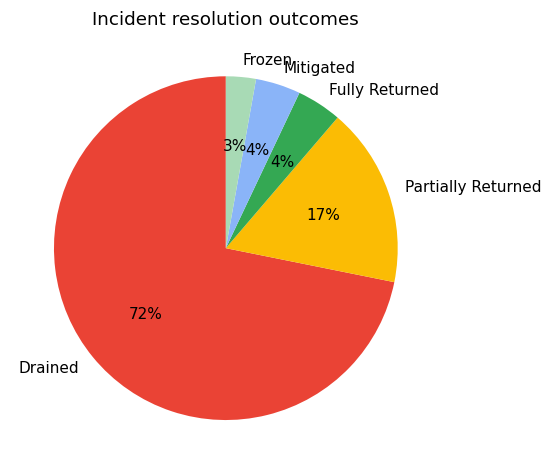

                           recovered    lost    pct
primary_category                                   
Bridge Vulnerability           325.0   325.0  100.0
Access Control                 631.5   632.0   99.9
Reentrancy                      24.0    25.0   96.0
Logic Error                    203.4   212.0   95.9
Oracle Manipulation             70.2   146.7   47.9
Infrastructure Compromise       43.0  1460.0    2.9


In [7]:
res = df['resolution'].value_counts()
fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.pie(res.values, labels=res.index, autopct='%1.0f%%', startangle=90,
       colors=['#ea4335','#fbbc04','#34a853','#8ab4f8','#a8dab5','#f28b82'])
ax.set_title('Incident resolution outcomes')
plt.show()

rec = df[df['recovered_usd_millions'] > 0].groupby('primary_category').agg(
    recovered=('recovered_usd_millions','sum'), lost=('loss_usd_millions','sum'))
rec['pct'] = 100*rec['recovered']/rec['lost']
print(rec.sort_values('pct', ascending=False).round(1))

## 8 · The SWC Catalog: A Tutor for Classifiers

The vulnerability table maps SWC IDs to Solidity code patterns, severity, and remediation — a ready-made base for text/code classification experiments.


In [8]:
print('Severity distribution:')
print(swc['typical_severity'].value_counts().to_string())
print('\nTop tool coverage (tools able to detect each class):')
swc['n_tools'] = swc['detectable_by'].str.split(',').str.len()
print(swc[['swc_id','name','n_tools']].sort_values('n_tools', ascending=False).head(8).to_string(index=False))

Severity distribution:
typical_severity
Medium      9
High        6
Critical    6
Low         6

Top tool coverage (tools able to detect each class):
 swc_id                                name  n_tools
SWC-106          Integer Overflow/Underflow        3
SWC-107                          Reentrancy        3
SWC-100         Function Default Visibility        2
SWC-119           Shadowing State Variables        2
SWC-104         Unchecked Call Return Value        2
SWC-114        Transaction Order Dependence        2
SWC-115         Authorization via tx.origin        2
SWC-124 Write to Arbitrary Storage Location        2


## Key Takeaways

| Insight | Evidence |
|---|---|
| **Code bugs ≠ the biggest losses** | Key/infrastructure compromise incidents (Ronin, Bybit) out-lose every code-bug class combined |
| **Reentrancy is tamed but alive** | Penpie (2024) shows callback reentrancy still works against modern protocols |
| **Medians mislead** | Median incident ≈ $8M, but the top-5 events carry ~45% of all documented losses |
| **Recovery is rare** | ~10–15% of incidents get funds fully back; negotiated returns are the main path |

### What next?
- Try a **classifier** mapping post-mortem text → SWC class using table 2
- Model **loss severity** per category with chain/category features from table 1
- Benchmark **tool coverage** gaps from table 3 against incident root causes

**If this helped, an upvote on the dataset and notebook goes a long way.** Questions and critiques welcome in the comments — especially from fellow auditors. 🛡️
